# # Experiment 6: Patching Smart
1) Aug(+) + AdamW + Fine Tuning: val_f1 0.4675
2) 

## ⚙️ **Libraries Import**

In [1]:
# Set seed for reproducibility
SEED = 100

import numpy as np

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
from pathlib import Path


# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
from torchsummary import summary
#from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision.transforms import v2 as transforms
from torch.utils.data import TensorDataset, DataLoader
#!pip install torchview
#from torchview import draw_graph

# Configurazione di TensorBoard e directory
#logs_dir = "tensorboard"
#!pkill -f tensorboard
#%load_ext tensorboard
#!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import cv2
import copy
import shutil
from itertools import product
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from PIL import Image
import matplotlib.gridspec as gridspec
import requests
from io import BytesIO

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.6.0+cu124
Device: cuda


## 🔧 **Automatic Configuration**

In [2]:
#(LOCAL vs KAGGLE)

def get_paths():
    """It detects the enviroment and returns the correct path."""
    if os.path.exists('/kaggle/input'):
        print("🌍 Detetected enviroment: KAGGLE")
        input_dir = Path('/kaggle/input/patching-spotdel/')
        output_dir = Path('/kaggle/working/')
    else:
        print("💻 Detetected enviroment: LOCAL")
        # Impostate la vostra cartella di input e output locali
        input_dir = Path('../data/archive/')
        output_dir = Path('../data/output/')

        # Crea le cartelle se non esistono in locale
        output_dir.mkdir(parents=True, exist_ok=True)

    return input_dir, output_dir

INPUT_DIR, OUTPUT_DIR = get_paths()
print(f"Input directory: {INPUT_DIR}")
print(f"Output directory: {OUTPUT_DIR}")
!ls '/kaggle/input/patching-spotdel/'

🌍 Detetected enviroment: KAGGLE
Input directory: /kaggle/input/patching-spotdel
Output directory: /kaggle/working
test_patches_groups.npy  train_patches_groups.npy  train_patches_masks.npy
test_patches_images.npy  train_patches_images.npy
test_patches_masks.npy	 train_patches_labels.npy


In [3]:
#creo cartella per i models
models_dir=OUTPUT_DIR/'models'
models_dir.mkdir(parents=True, exist_ok=True)

## **Constants**

In [4]:
#tutte le costanti utili in un unico posto :)

BATCH_SIZE = 256

# ImageNet normalization statistics
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)


## ⏳ **Data Loading**

In [5]:
PATCHES_DIR = INPUT_DIR  

# --- Load Training Patches ---
# Load images 
train_images = np.load(PATCHES_DIR / 'train_patches_images.npy').astype('float32')
train_groups = np.load(PATCHES_DIR / 'train_patches_groups.npy')

train_labels_array = np.load(PATCHES_DIR / 'train_patches_labels.npy')
train_labels = pd.DataFrame(train_labels_array, columns=['label'])
# --- OPTIONAL: Map integers back to class names ---
# If your npy file has integers (0-3) and you want the string names in the CSV:
label_mapping_inv = {
    0: 'Luminal A',
    1: 'Luminal B',
    2: 'HER2(+)',
    3: 'Triple negative'
}
train_labels['label'] = train_labels['label'].map(label_mapping_inv)
#df.to_csv('train_patches_labels.csv', index=False)
#print(train_labels.head())

# Optional: Load masks if you need them (though MobileNet classification usually doesn't)
# train_masks = np.load(PATCHES_DIR / 'train_patches_masks.npy').astype('float32')

print("Data loaded sucessfully!")
print(f"Train images shape: {train_images.shape}")
print(f"Train labels shape: {train_labels.shape}")
print(f"Train groups shape: {train_groups.shape}")

Data loaded sucessfully!
Train images shape: (5640, 224, 224, 3)
Train labels shape: (5640, 1)
Train groups shape: (5640,)


## 🔎 **Data Analysis**

In [6]:
#LABELS ANALYSIS AND DISTRIBUTION
print(train_labels.describe())

print("\n--- Unique Labels ---")
unique_labels = train_labels['label'].unique()
print(unique_labels)

print("\n--- Label Distribution ---")
label_counts = train_labels['label'].value_counts()
label_percentages = train_labels['label'].value_counts(normalize=True) * 100
label_stats = pd.DataFrame({
    'count': label_counts,
    'percentage': label_percentages
})
print(label_stats.round(2))

            label
count        5640
unique          4
top     Luminal B
freq         1979

--- Unique Labels ---
['Triple negative' 'Luminal B' 'Luminal A' 'HER2(+)']

--- Label Distribution ---
                 count  percentage
label                             
Luminal B         1979       35.09
HER2(+)           1551       27.50
Luminal A         1522       26.99
Triple negative    588       10.43


In [7]:
#number of classes
NUM_CLASSES = len(unique_labels)

## 🔄 **Data Processing**

In [8]:
# Target preparation

# Define the mapping between textual labels and numerical value (enum)
label_mapping = {
    'Luminal A': 0,
    'Luminal B': 1,
    'HER2(+)': 2,
    'Triple negative': 3
}

# Add new column 'target' to train_labels dataframe
train_labels['target'] = train_labels['label'].map(label_mapping)

target = np.array(train_labels['target']).astype('float32')

In [9]:
# --- Calculate Class Weights (Important for Patches) ---
# Patch distribution might differ from original image distribution

# weight = (num_total_training / (num_classes * num_for_class))
# Reindex label_stats to follow the explicit mapping order instead of alphabetical order
ordered_labels = [label for label, _ in sorted(label_mapping.items(), key=lambda kv: kv[1])]
label_stats_ordered = label_stats.reindex(ordered_labels)
class_weights = (len(train_labels) / (NUM_CLASSES * label_stats_ordered['count'])).astype(np.float32)

# Create list useful later for tensor transformation
class_weights_list = list(class_weights)
print(f"Balanced WEIGHT for each class:\t{class_weights_list}")
print(f"Class order: {ordered_labels}")
class_weights_tensor = torch.tensor(class_weights_list, dtype=torch.float32).to(device)


Balanced WEIGHT for each class:	[0.9264126420021057, 0.7124810218811035, 0.9090909361839294, 2.3979592323303223]
Class order: ['Luminal A', 'Luminal B', 'HER2(+)', 'Triple negative']


In [10]:
from sklearn.model_selection import GroupShuffleSplit
# --- 3. Group-Aware Split (Train/Val) ---
# We must use groups to prevent leakage (patches from same image must stay together)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, val_idx = next(gss.split(train_images, train_labels, groups=train_groups))

X_train, X_val = train_images[train_idx], train_images[val_idx]
y_train, y_val = target[train_idx], target[val_idx]
# If you used masks:
# train_masks, val_masks = train_masks[train_idx], train_masks[val_idx]

# Print the shapes of the resulting datasets
print("\n--- Split Results ---")
print("Training Data Shape:", X_train.shape)
print("Training Label Shape:", y_train.shape)
print("Validation Data Shape:", X_val.shape)
print("Validation Label Shape:", y_val.shape)


--- Split Results ---
Training Data Shape: (4506, 224, 224, 3)
Training Label Shape: (4506,)
Validation Data Shape: (1134, 224, 224, 3)
Validation Label Shape: (1134,)


In [11]:
# Define the input shape based on the training data
INPUT_SHAPE = (X_train.shape[3], X_train.shape[1], X_train.shape[2])
print(INPUT_SHAPE)

(3, 224, 224)


In [12]:
class MyDataset(torch.utils.data.Dataset):
    """Custom PyTorch Dataset with optional augmentation and normalization."""

    def __init__(self, data, labels, augmentation=None, normalize_imagenet=False):
        """
        Args:
            data: numpy array of images (N, C, H, W) in range [0, 1]
            labels: numpy array of labels
            augmentation: transforms for data augmentation
            normalize_imagenet: whether to apply ImageNet normalization
        """
        self.data = torch.from_numpy(data).permute(0, 3, 1, 2)
        self.labels = torch.from_numpy(labels).squeeze().long()
        self.augmentation = augmentation
        self.normalize_imagenet = normalize_imagenet

        # ImageNet normalization transform
        if normalize_imagenet:
            self.normalize = transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
        else:
            self.normalize = None

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image = self.data[idx].clone()  # Clone to avoid modifying original
        label = self.labels[idx]

        # Apply augmentation if provided (on images in [0, 1] range)
        if self.augmentation:
            image = self.augmentation(image)

        # Apply ImageNet normalization if requested
        if self.normalize:
            image = self.normalize(image)

        return image, label

In [13]:
train_transforms = transforms.Compose([ 
    transforms.RandomHorizontalFlip(p=0.1),
    #transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    #transforms.RandomVerticalFlip(p=0.1),
    transforms.RandomRotation(180),
    #transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.05),
])

# Convert numpy arrays to customized PyTorch datasets (pairs features with labels)
train_ds = MyDataset(X_train, y_train, augmentation=None, normalize_imagenet=True)
val_ds   = MyDataset(X_val, y_val, augmentation=None, normalize_imagenet=True)

In [14]:
def make_loader(ds, batch_size, shuffle, drop_last):
    # Determine optimal number of worker processes for data loading
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    # Create DataLoader with performance optimizations
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,  # Faster GPU transfer
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,  # Load 4 batches ahead
    )

In [15]:
# Create data loaders with different settings for each phase
train_loader = make_loader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader   = make_loader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

In [16]:
# print batch shape
for xb, yb in train_loader:
    print("Features batch shape:", xb.shape)
    print("Labels batch shape:", yb.shape)
    break # Stop after getting one batch

Features batch shape: torch.Size([256, 3, 224, 224])
Labels batch shape: torch.Size([256])


## 🧮 **Network Parameters**

In [17]:
# Training parameters
LEARNING_RATE = 0.001
EPOCHS = 200
PATIENCE = 20


# Regularisation
DROPOUT_RATE = 0.4      # Dropout probability
L1_LAMBDA = 0.001           # L1 penalty 
L2_LAMBDA = 0.005           # L2 penalty 

# Set up loss function
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

##  🧠 **Training Functions**

In [18]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device):
    """Train for one epoch."""
    model.train()

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            logits = model(inputs)
            loss = criterion(logits, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * inputs.size(0)
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='macro'
    )

    return epoch_loss, epoch_f1


def validate_one_epoch(model, val_loader, criterion, device):
    """Validate for one epoch."""
    model.eval()

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)

            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(inputs)
                loss = criterion(logits, targets)

            running_loss += loss.item() * inputs.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='macro'
    )

    return epoch_loss, epoch_f1


def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler, device,
        patience=0, evaluation_metric="val_f1", mode='max',
        restore_best_weights=True, verbose=1, experiment_name=""):
    """Train the neural network model."""

    training_history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [], 'val_f1': []
    }

    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0

    print(f"Training {epochs} epochs...")

    for epoch in range(1, epochs + 1):
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device
        )

        val_loss, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )

        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)

        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | "
                    f"Train: Loss={train_loss:.4f}, F1={train_f1:.4f} | "
                    f"Val: Loss={val_loss:.4f}, F1={val_f1:.4f}")

        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), OUTPUT_DIR/'models'/(experiment_name+'_model.pt'))
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load(OUTPUT_DIR/'models'/(experiment_name+'_model.pt')))
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    if patience == 0:
        torch.save(model.state_dict(), OUTPUT_DIR/'models'/(experiment_name+'_model.pt'))

    return model, training_history

## 🛠️ **Learning**

In [19]:
# --- 1. Feature Extractor (Frozen ResNet50) ---
class FeatureExtractor(nn.Module):
    def __init__(self):
        super().__init__()
        # Use ResNet50 - standard for pathology feature extraction
        weights = torchvision.models.ResNet50_Weights.DEFAULT
        self.backbone = torchvision.models.resnet50(weights=weights)
        # Remove the classification head (fc layer)
        self.backbone.fc = nn.Identity()
        
        # Freeze all weights
        for param in self.backbone.parameters():
            param.requires_grad = False
            
    def forward(self, x):
        # Output shape: (Batch_Size, 2048)
        return self.backbone(x)
        

# --- 2. Extract Features Helper Function ---
def extract_features(images, batch_size=64, device='cuda'):
    """Converts a numpy array of images (N, 224, 224, 3) into features (N, 2048)"""
    # Create simple dataset/loader for speed
    dataset = MyDataset(images, np.zeros(len(images)), augmentation=None, normalize_imagenet=True)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True)
    
    model = FeatureExtractor().to(device)
    model.eval()
    
    features_list = []
    
    print("Extracting features...")
    with torch.no_grad():
        for inputs, _ in loader:
            inputs = inputs.to(device)
            # Forward pass only
            feats = model(inputs)
            features_list.append(feats.cpu().numpy())
            
    return np.concatenate(features_list) # Shape: (N_samples, 2048)


# --- EXECUTE EXTRACTION ---
# We extract features for Train and Val separately based on your previous split
print("Extracting features for Training set...")
X_train_features = extract_features(X_train, device=device) # Input: Your X_train images
print(f"Train Features Shape: {X_train_features.shape}")

print("Extracting features for Validation set...")
X_val_features = extract_features(X_val, device=device)     # Input: Your X_val images
print(f"Val Features Shape: {X_val_features.shape}")

Extracting features for Training set...


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 182MB/s] 


Extracting features...
Train Features Shape: (4506, 2048)
Extracting features for Validation set...
Extracting features...
Val Features Shape: (1134, 2048)


In [20]:
def create_bags(features, labels, group_ids):
    """
    Groups features by Slide ID.
    Returns:
        bags: List of Tensors. Each tensor is (N_patches, 2048)
        bag_labels: List of integers (Label for the slide)
    """
    # Create a dataframe to handle grouping
    # Ensure labels are simple integers for grouping
    df = pd.DataFrame({
        'group_id': group_ids,
        'label': labels,
        'feat_idx': range(len(features))
    })
    
    unique_slides = df['group_id'].unique()
    bags = []
    bag_labels = []
    
    print(f"Creating bags for {len(unique_slides)} unique slides...")
    
    for slide_id in unique_slides:
        slide_df = df[df['group_id'] == slide_id]
        
        # Get all features for this slide
        indices = slide_df['feat_idx'].values
        slide_feats = features[indices] # Shape: (N_patches_in_slide, 2048)
        
        # Get label (they should be identical for one slide)
        # FIX: Explicitly cast numpy.float32 to python int
        slide_label = int(slide_df['label'].iloc[0])
        
        bags.append(torch.tensor(slide_feats, dtype=torch.float32))
        bag_labels.append(torch.tensor(slide_label, dtype=torch.long))
        
    return bags, bag_labels



# --- EXECUTE BAG CREATION ---
# Ensure we define the split groups first (from your previous cells)
train_groups_split = train_groups[train_idx]
val_groups_split = train_groups[val_idx]

# Create Training Bags
train_bags, train_labels_mil = create_bags(X_train_features, y_train, train_groups_split)

# Create Validation Bags
val_bags, val_labels_mil = create_bags(X_val_features, y_val, val_groups_split)

print(f"Created {len(train_bags)} Training Bags")
print(f"Created {len(val_bags)} Validation Bags")

Creating bags for 503 unique slides...
Creating bags for 126 unique slides...
Created 503 Training Bags
Created 126 Validation Bags


In [21]:
class GatedAttentionMIL(nn.Module):
    def __init__(self, input_dim=2048, num_classes=4):
        super().__init__()
        self.L = 512
        self.D = 128
        self.K = 1

        self.feature_extractor = nn.Sequential(
            nn.Linear(input_dim, self.L),
            nn.ReLU(),
            nn.Dropout(0.5) # Increased dropout from 0.3 to 0.5 for regularization
        )

        # Gated Attention Mechanism
        self.attention_V = nn.Sequential(
            nn.Linear(self.L, self.D),
            nn.Tanh()
        )
        
        self.attention_U = nn.Sequential(
            nn.Linear(self.L, self.D),
            nn.Sigmoid()
        )

        self.attention_weights = nn.Linear(self.D, self.K)

        self.classifier = nn.Sequential(
            nn.Linear(self.L * self.K, num_classes)
        )

    def forward(self, x):
        # 1. Compress features
        H = self.feature_extractor(x) # [N, 512]

        # 2. Gated Attention
        A_V = self.attention_V(H)  # [N, 128]
        A_U = self.attention_U(H)  # [N, 128]
        
        # Element-wise multiplication (Gating)
        A = self.attention_weights(A_V * A_U) # [N, 1]
        A = torch.softmax(A, dim=0) 

        # 3. Aggregate
        M = torch.mm(A.transpose(0, 1), H)  # [1, 512]

        # 4. Classify
        logits = self.classifier(M)
        return logits, A

In [22]:
def train_one_epoch_mil(model, bags, labels, criterion, optimizer, device):
    """Train MIL model for one epoch."""
    model.train()
    running_loss = 0.0
    all_predictions = []
    all_targets = []
    
    # Shuffle bags for stochastic training
    indices = np.arange(len(bags))
    np.random.shuffle(indices)
    
    for i in indices:
        bag = bags[i].to(device)
        # Label must be shape [1] for CrossEntropy
        label = labels[i].unsqueeze(0).to(device) 
        
        optimizer.zero_grad()
        
        logits, _ = model(bag)
        loss = criterion(logits, label)
        
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        
        # Store for metrics
        pred = logits.argmax(dim=1).item()
        all_predictions.append(pred)
        all_targets.append(label.item())
        
    epoch_loss = running_loss / len(bags)
    epoch_f1 = f1_score(all_targets, all_predictions, average='macro')
    
    return epoch_loss, epoch_f1

def validate_one_epoch_mil(model, bags, labels, criterion, device):
    """Validate MIL model."""
    model.eval()
    running_loss = 0.0
    all_predictions = []
    all_targets = []
    
    with torch.no_grad():
        for i in range(len(bags)):
            bag = bags[i].to(device)
            label = labels[i].unsqueeze(0).to(device)
            
            logits, _ = model(bag)
            loss = criterion(logits, label)
            
            running_loss += loss.item()
            pred = logits.argmax(dim=1).item()
            all_predictions.append(pred)
            all_targets.append(label.item())
            
    epoch_loss = running_loss / len(bags)
    epoch_f1 = f1_score(all_targets, all_predictions, average='macro')
    
    return epoch_loss, epoch_f1, all_predictions, all_targets

def fit_mil(model, train_bags, train_labels, val_bags, val_labels, 
            epochs, criterion, optimizer, device, patience=10, 
            experiment_name="mil_experiment"):
    """
    Main training loop for MIL, matching your original structure.
    """
    
    history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [], 'val_f1': []
    }
    
    best_val_f1 = 0.0
    patience_counter = 0
    best_epoch = 0
    
    print(f"Starting MIL Training for {epochs} epochs...")
    
    for epoch in range(1, epochs + 1):
        # 1. Train
        t_loss, t_f1 = train_one_epoch_mil(
            model, train_bags, train_labels, criterion, optimizer, device
        )
        
        # 2. Validate
        v_loss, v_f1, _, _ = validate_one_epoch_mil(
            model, val_bags, val_labels, criterion, device
        )
        
        # 3. Log
        history['train_loss'].append(t_loss)
        history['val_loss'].append(v_loss)
        history['train_f1'].append(t_f1)
        history['val_f1'].append(v_f1)
        
        print(f"Epoch {epoch:03d}/{epochs} | "
              f"Train Loss: {t_loss:.4f} F1: {t_f1:.4f} | "
              f"Val Loss: {v_loss:.4f} F1: {v_f1:.4f}")
        
        # 4. Checkpointing & Early Stopping
        if v_f1 > best_val_f1:
            best_val_f1 = v_f1
            best_epoch = epoch
            patience_counter = 0
            torch.save(model.state_dict(), OUTPUT_DIR / f"{experiment_name}_best.pt")
        else:
            patience_counter += 1
            
        if patience_counter >= patience:
            print(f"\nEarly stopping triggered at epoch {epoch}.")
            break
            
    # Restore best model
    print(f"\nLoading best model from epoch {best_epoch} with Val F1: {best_val_f1:.4f}")
    model.load_state_dict(torch.load(OUTPUT_DIR / f"{experiment_name}_best.pt"))
    
    return model, history

In [23]:
# --- Setup ---
mil_model = GatedAttentionMIL(input_dim=2048, num_classes=4).to(device)

# Using a smaller learning rate for MIL usually helps stability
optimizer = torch.optim.AdamW(mil_model.parameters(), lr=0.00001, weight_decay=1e-3)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

# --- Run Training ---
best_mil_model, mil_history = fit_mil(
    model=mil_model,
    train_bags=train_bags,      # From 'create_bags' step
    train_labels=train_labels_mil, 
    val_bags=val_bags,          # From 'create_bags' step
    val_labels=val_labels_mil,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    patience=30,
    experiment_name="AttentionMIL_Run1"
)

Starting MIL Training for 200 epochs...
Epoch 001/200 | Train Loss: 7.7315 F1: 0.2742 | Val Loss: 4.3001 F1: 0.1123
Epoch 002/200 | Train Loss: 7.1636 F1: 0.2627 | Val Loss: 3.3516 F1: 0.1429
Epoch 003/200 | Train Loss: 6.4352 F1: 0.2765 | Val Loss: 3.5226 F1: 0.1234
Epoch 004/200 | Train Loss: 5.8855 F1: 0.2624 | Val Loss: 2.4055 F1: 0.3174
Epoch 005/200 | Train Loss: 5.2916 F1: 0.2729 | Val Loss: 3.1227 F1: 0.2104
Epoch 006/200 | Train Loss: 5.1107 F1: 0.2643 | Val Loss: 3.0794 F1: 0.1548
Epoch 007/200 | Train Loss: 4.8172 F1: 0.2569 | Val Loss: 2.2782 F1: 0.1837
Epoch 008/200 | Train Loss: 4.4222 F1: 0.2695 | Val Loss: 2.1050 F1: 0.2389
Epoch 009/200 | Train Loss: 3.8432 F1: 0.3032 | Val Loss: 2.1921 F1: 0.2339
Epoch 010/200 | Train Loss: 3.4377 F1: 0.3087 | Val Loss: 3.2619 F1: 0.1520
Epoch 011/200 | Train Loss: 3.2092 F1: 0.2841 | Val Loss: 1.7697 F1: 0.3037
Epoch 012/200 | Train Loss: 2.8790 F1: 0.3086 | Val Loss: 1.9897 F1: 0.2491
Epoch 013/200 | Train Loss: 2.7036 F1: 0.3001 | 

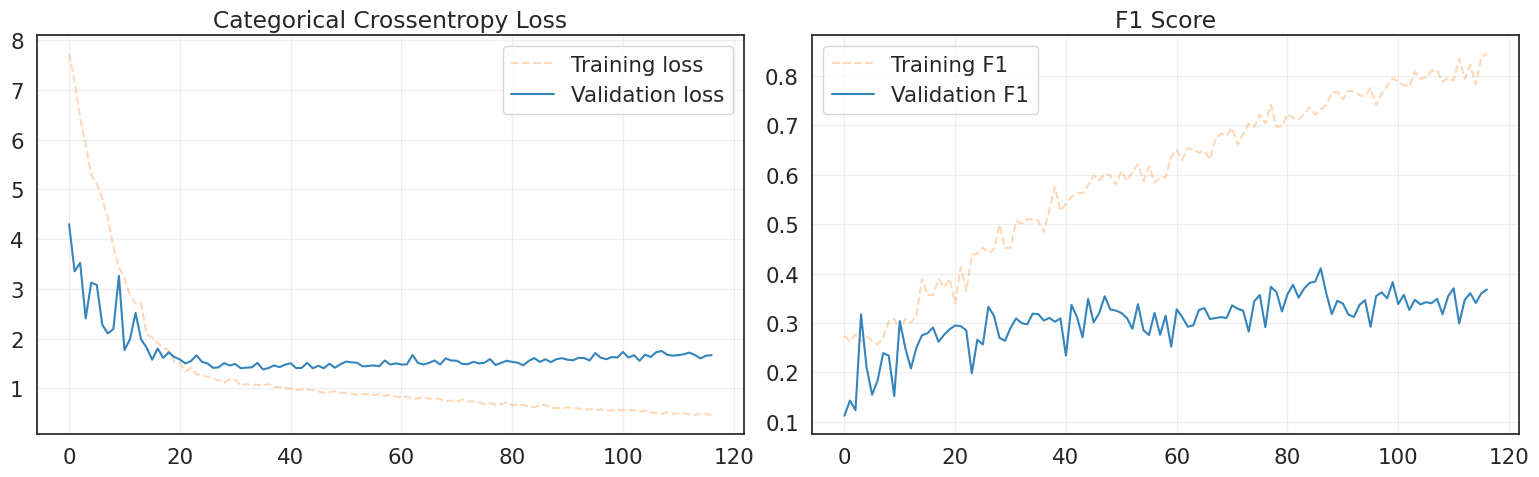

In [24]:
# @title Plot History
# Create a figure with two side-by-side subplots
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(mil_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(mil_history['val_loss'], label='Validation loss', alpha=0.9, color='#1f77b4')
ax1.set_title('Categorical Crossentropy Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation Accuracy on the second axis
ax2.plot(mil_history['train_f1'], label='Training F1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(mil_history['val_f1'], label='Validation F1', alpha=0.9, color='#1f77b4')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Running inference on validation bags...
Accuracy over the validation set: 0.4524
Precision over the validation set: 0.4959
Recall over the validation set: 0.4524
F1 score over the validation set: 0.4378
-----------------------------------
CLASS                ACCURACY
-----------------------------------
Luminal A            48.48%
Luminal B            45.24%
HER2(+)              60.61%
Triple negative      11.11%
-----------------------------------


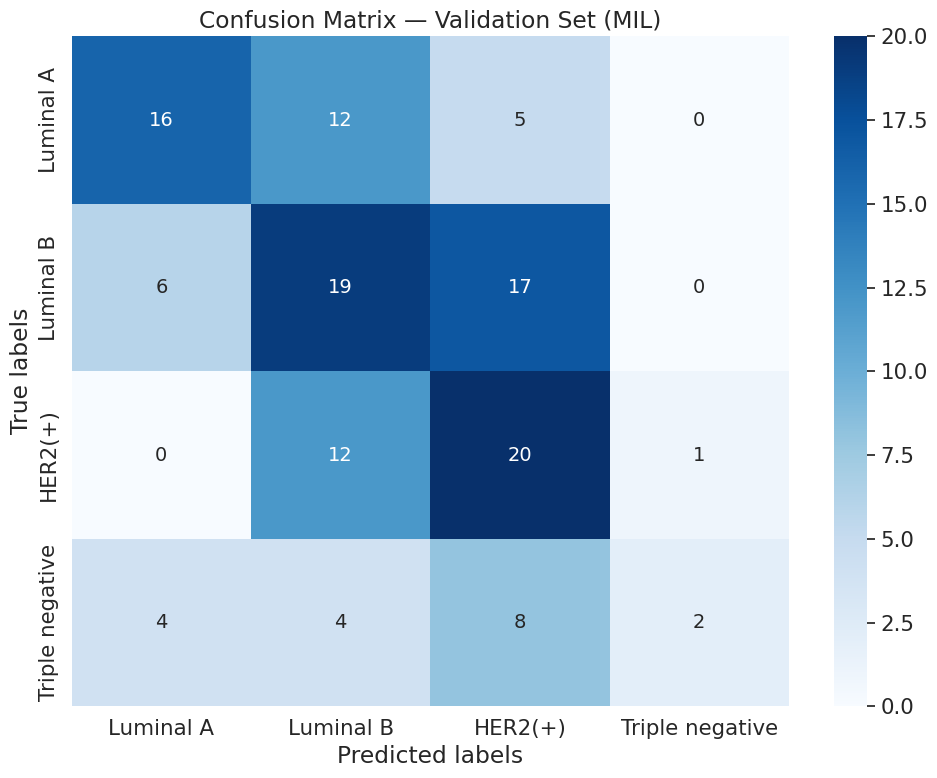

In [25]:
# @title Plot Confusion Matrix & Metrics

# Collect predictions and ground truth labels
class_labels = ['Luminal A', 'Luminal B', 'HER2(+)', 'Triple negative']

val_preds, val_targets = [], []
best_mil_model.eval() # Ensure model is in eval mode

print("Running inference on validation bags...")
with torch.no_grad():  # Disable gradient computation for inference
    # Iterate over the Bag List (instead of a DataLoader)
    for i in range(len(val_bags)):
        bag = val_bags[i].to(device)
        label = val_labels_mil[i].item() # Get integer label

        # Forward pass: get model predictions
        logits, _ = best_mil_model(bag)
        pred = logits.argmax(dim=1).item()

        # Store results
        val_preds.append(pred)
        val_targets.append(label)

# Convert to numpy arrays for compatibility
val_preds = np.array(val_preds)
val_targets = np.array(val_targets)

# Calculate overall validation metrics
val_acc = accuracy_score(val_targets, val_preds)
val_prec = precision_score(val_targets, val_preds, average='weighted')
val_rec = recall_score(val_targets, val_preds, average='weighted')
val_f1 = f1_score(val_targets, val_preds, average='weighted')

print(f"Accuracy over the validation set: {val_acc:.4f}")
print(f"Precision over the validation set: {val_prec:.4f}")
print(f"Recall over the validation set: {val_rec:.4f}")
print(f"F1 score over the validation set: {val_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_targets, val_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Store accuracy per class with desired names
# Calcola il totale per ogni classe reale (somma delle righe)
true_totals = cm.sum(axis=1)
# Normalizza la matrice (gestendo la divisione per zero)
cm_perc = np.divide(cm.astype(float), true_totals[:, None], out=np.zeros_like(cm, dtype=float), where=true_totals[:, None]>0)
# Estrai la diagonale (che è l'accuratezza per ogni classe)
per_class_accuracy = cm_perc.diagonal()

# Safe access to indices (in case some classes are missing in val set)
accuracy_LA = per_class_accuracy[0] if len(per_class_accuracy) > 0 else 0.0
accuracy_LB = per_class_accuracy[1] if len(per_class_accuracy) > 1 else 0.0
accuracy_H2 = per_class_accuracy[2] if len(per_class_accuracy) > 2 else 0.0
accuracy_TN = per_class_accuracy[3] if len(per_class_accuracy) > 3 else 0.0

print("-" * 35)
print(f"{'CLASS':<20} {'ACCURACY'}")
print("-" * 35)

print(f"{'Luminal A':<20} {accuracy_LA:.2%}")
print(f"{'Luminal B':<20} {accuracy_LB:.2%}")
print(f"{'HER2(+)':<20} {accuracy_H2:.2%}")
print(f"{'Triple negative':<20} {accuracy_TN:.2%}")
print("-" * 35)

# Visualise confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues',
            xticklabels=class_labels,
            yticklabels=class_labels
            )
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set (MIL)')
plt.tight_layout()
plt.show()

## 🕹️ **Test Inference**

In [29]:
# --- 1. Define Gated Attention MIL (Must match training architecture) ---
class AttentionMIL(nn.Module):
    def __init__(self, input_dim=2048, num_classes=4, dropout_rate=0.5):
        super().__init__()
        self.L = 512
        self.D = 128
        self.K = 1

        self.feature_extractor = nn.Sequential(
            nn.Linear(input_dim, self.L),
            nn.ReLU(),
            nn.Dropout(dropout_rate)
        )

        # Gated Attention Mechanism
        self.attention_V = nn.Sequential(nn.Linear(self.L, self.D), nn.Tanh())
        self.attention_U = nn.Sequential(nn.Linear(self.L, self.D), nn.Sigmoid())
        self.attention_weights = nn.Linear(self.D, self.K)

        self.classifier = nn.Sequential(
            nn.Linear(self.L * self.K, num_classes)
        )

    def forward(self, x):
        # No patch dropout during inference
        
        # 1. Compress features
        H = self.feature_extractor(x) 

        # 2. Gated Attention
        A_V = self.attention_V(H)
        A_U = self.attention_U(H)
        A = self.attention_weights(A_V * A_U) # Element-wise multiplication
        A = torch.softmax(A, dim=0)           # Normalize attention scores

        # 3. Aggregate
        M = torch.mm(A.transpose(0, 1), H)    

        # 4. Classify
        logits = self.classifier(M)
        return logits, A

# --- 2. Extract Features for Test Set ---
print("Loading Test Images...")
test_images = np.load(PATCHES_DIR / 'test_patches_images.npy').astype('float32')
test_groups = np.load(PATCHES_DIR / 'test_patches_groups.npy')

print(f"Extracting features for {len(test_images)} test patches...")
# Uses the extract_features function you defined earlier
X_test_features = extract_features(test_images, device=device)
print(f"Test Features Shape: {X_test_features.shape}")

# --- 3. Create Test Bags ---
def create_test_bags(features, group_ids):
    """Groups features by Slide ID for inference."""
    df = pd.DataFrame({
        'group_id': group_ids,
        'feat_idx': range(len(features))
    })
    
    unique_slides = df['group_id'].unique()
    bags = []
    bag_ids = []
    
    print(f"Grouping into {len(unique_slides)} slides...")
    for slide_id in unique_slides:
        slide_df = df[df['group_id'] == slide_id]
        indices = slide_df['feat_idx'].values
        slide_feats = features[indices]
        
        bags.append(torch.tensor(slide_feats, dtype=torch.float32))
        bag_ids.append(slide_id)
        
    return bags, bag_ids

test_bags, test_ids = create_test_bags(X_test_features, test_groups)

# --- 2. Load Model ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
inference_model = AttentionMIL(input_dim=2048, num_classes=4).to(device)

# Load weights (Ensure this points to your latest trained model)
weights_path = OUTPUT_DIR / "best_mil_model.pt" 
# fallback check
if not weights_path.exists():
     weights_path = OUTPUT_DIR / "AttentionMIL_Run1_best.pt"

print(f"Loading weights from: {weights_path}")
inference_model.load_state_dict(torch.load(weights_path))
inference_model.eval()

# --- 3. Run Prediction Loop ---
# Assuming 'test_bags' and 'test_ids' are already created from the previous step
print(f"Running Inference on {len(test_bags)} slides...")
test_preds = []

with torch.no_grad():
    for i in range(len(test_bags)):
        bag = test_bags[i].to(device)
        logits, _ = inference_model(bag)
        pred = logits.argmax(dim=1).item()
        test_preds.append(pred)

# --- 4. Create & SORT Submission DataFrame ---
target_to_label = {
    0: 'Luminal A',
    1: 'Luminal B',
    2: 'HER2(+)',
    3: 'Triple negative'
}

submission_df = pd.DataFrame({
    'sample_index': test_ids,
    'label_code': test_preds
})

# Map codes to strings
submission_df['label'] = submission_df['label_code'].map(target_to_label)

# --- CRITICAL STEP: SORTING ---
# 1. Sort by sample_index to ensure img_0000 comes before img_0001
submission_df = submission_df.sort_values(by='sample_index')

# Optional: If your 'test_ids' are raw numbers (0, 1, 2) and you need 'img_0000.png',
# uncomment the following line to format them:
#submission_df['sample_index'] = submission_df['sample_index'].apply(lambda x: f"img_{int(x):04d}.png")

# Select final columns
final_submission = submission_df[['sample_index', 'label']]

# Save
csv_path = OUTPUT_DIR / 'submission.csv'
final_submission.to_csv(csv_path, index=False)

print(f"✅ Submission sorted and saved to: {csv_path}")
print("First 5 rows:")
print(final_submission.head())

Loading Test Images...
Extracting features for 2500 test patches...
Extracting features...
Test Features Shape: (2500, 2048)
Grouping into 477 slides...
Loading weights from: /kaggle/working/AttentionMIL_Run1_best.pt
Running Inference on 477 slides...
✅ Submission sorted and saved to: /kaggle/working/submission.csv
First 5 rows:
     sample_index            label
229  img_0000.png          HER2(+)
396  img_0001.png  Triple negative
457  img_0002.png        Luminal B
31   img_0003.png        Luminal B
317  img_0004.png        Luminal A
